## EDA

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find the project root, whether this notebook is in notebooks/ or the root
possible_paths = [
    Path("../data/raw/national_toilets.csv"),
    Path("data/raw/national_toilets.csv"),
]

csv_path = next((p for p in possible_paths if p.exists()), None)

if csv_path is None:
    raise FileNotFoundError(
        "Couldn't find national_toilets.csv. Check the notebook's location."
    )

toilets = pd.read_csv(csv_path)

print(f"Dataset shape: {toilets.shape[0]:,} rows × {toilets.shape[1]} columns")
display(toilets.head())


Matplotlib is building the font cache; this may take a moment.


Dataset shape: 25,624 rows × 48 columns


,_id,FacilityID,URL,Name,FacilityType,Address1,Town,State,AddressNote,Latitude,...,Ambulant,Accessible,LHTransfer,RHTransfer,ToiletNote,SharpsDisposal,DrinkingWater,SanitaryDisposal,MensPadDisposal,Shower
0,1,1,https://toiletmap.gov.au/facility/1,Sandy Beach Reserve,Park or reserve,"Lost 15525, West Road",Bassendean,WA,NaN,-31.921836,...,False,True,False,False,NaN,True,True,True,False,False
1,2,2,https://toiletmap.gov.au/facility/2,Point Reserve,Park or reserve,"Lot 197, North Road",Bassendean,WA,NaN,-31.904410,...,False,True,False,False,NaN,True,True,True,False,False
2,3,3,https://toiletmap.gov.au/facility/3,Success Hill Reserve,Park or reserve,"Lot 2838, Seventh Avenue",Bassendean,WA,NaN,-31.896289,...,False,True,False,False,NaN,True,False,True,False,False
3,4,4,https://toiletmap.gov.au/facility/4,Jubilee Reserve,Park or reserve,"Lot 6322, Robinson Road",Eden Hill,WA,NaN,-31.891474,...,False,False,False,False,NaN,True,False,True,False,False
4,5,5,https://toiletmap.gov.au/facility/5,Ashfield Reserve,Park or reserve,"Lot 12061, 2 Coulston Road",Ashfield,WA,NaN,-31.913433,...,False,True,False,False,NaN,True,True,True,False,False


In [ ]:

# Column names and data types
schema = pd.DataFrame({
    "column": toilets.columns,
    "dtype": toilets.dtypes.astype(str).values,
    "non_null": toilets.notna().sum().values,
    "missing": toilets.isna().sum().values,
    "missing_%": (toilets.isna().mean().values * 100).round(1),
})

display(schema.sort_values("missing_%", ascending=False))


,column,dtype,non_null,missing,missing_%
24,AdultChangeNote,str,236,25388,99.1
31,DumpPointNote,str,254,25370,99.0
27,BabyChangeNote,str,288,25336,98.9
18,AccessNote,str,1977,23647,92.3
13,ParkingNote,str,2104,23520,91.8
8,AddressNote,str,2943,22681,88.5
33,OpeningHoursNote,str,3579,22045,86.0
42,ToiletNote,str,4725,20899,81.6
5,Address1,str,25514,110,0.4
35,Female,bool,25624,0,0.0


## cleaning

In [11]:

import pandas as pd

# Load the original dataset
toilets = pd.read_csv("../data/raw/national_toilets.csv")

# Select NSW records within a rough Sydney bounding box
sydney = toilets[
    (toilets["State"] == "NSW") &
    (toilets["Longitude"].between(150.45, 151.45)) &
    (toilets["Latitude"].between(-34.25, -33.35))
].copy()

# Keep only the columns we need initially
columns = [
    "FacilityID", "Name", "FacilityType",
    "Town", "Latitude", "Longitude"
]

sydney = sydney[columns]

# Save as a separate CSV
sydney.to_csv("../data/processed/sydney_toilets.csv", index=False)

print(f"Saved {len(sydney)} toilet records.")
display(sydney.head())


Saved 3166 toilet records.


,FacilityID,Name,FacilityType,Town,Latitude,Longitude
204,306,Valentia Street Wharf,Other,Woolwich,-33.838470,151.176174
205,308,Weil Park,Park or reserve,Woolwich,-33.840420,151.167966
206,309,Gladesville Reserve,Park or reserve,Henley,-33.840998,151.137324
207,310,Boronia Park Oval,Park or reserve,Hunters Hill,-33.826388,151.137961
208,311,Buffalo Creek Reserve,Park or reserve,Hunters Hill,-33.816049,151.137360


In [12]:

import pandas as pd
import h3

# Load our filtered toilet locations
toilets = pd.read_csv("../data/processed/sydney_toilets.csv")

# Assign each toilet to an H3 hexagon.
# Resolution 9 gives hexagons roughly 0.1 km² in area.
toilets["hex_id"] = toilets.apply(
    lambda row: h3.latlng_to_cell(
        row["Latitude"], row["Longitude"], 9
    ),
    axis=1
)

# Count toilets in each hexagon
toilet_counts = (
    toilets.groupby("hex_id")
    .size()
    .reset_index(name="toilet_count")
)

print("Toilets:", len(toilets))
print("Hexagons containing toilets:", len(toilet_counts))

display(toilet_counts.head(10))

toilet_counts.to_csv(
    "../data/processed/toilet_counts_by_hex.csv",
    index=False
)


Toilets: 3166
Hexagons containing toilets: 2409


,hex_id,toilet_count
0,89be080b603ffff,1
1,89be080b613ffff,2
2,89be080b683ffff,1
3,89be080b68fffff,1
4,89be080b69bffff,2
5,89be0811a63ffff,1
6,89be0811b63ffff,1
7,89be081200fffff,2
8,89be08120abffff,1
9,89be0812307ffff,1


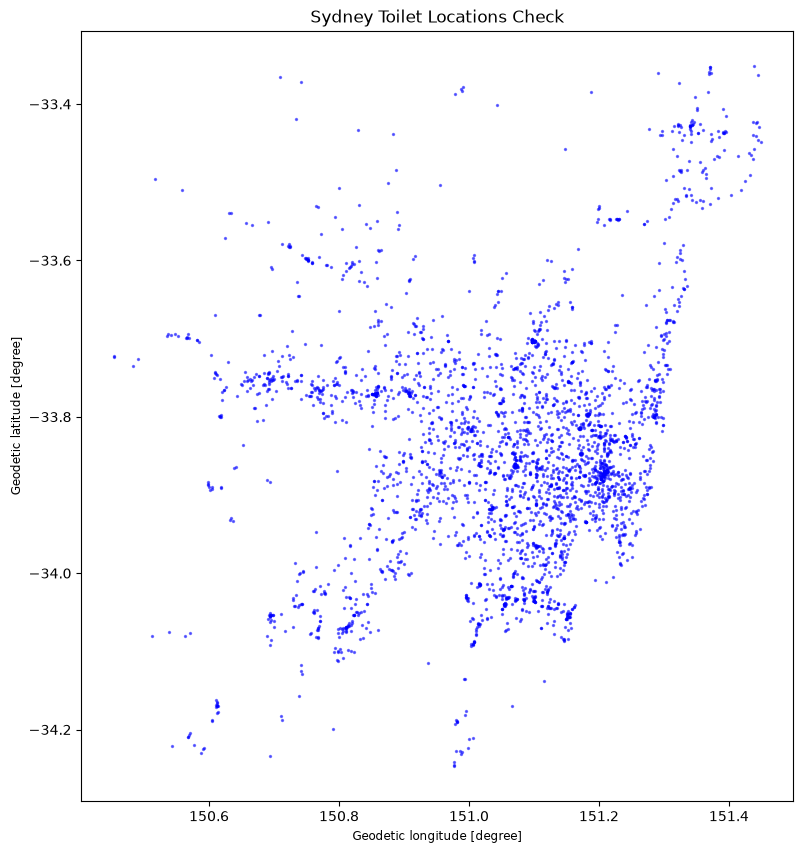

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Convert your toilets dataframe to a GeoDataFrame
gdf_toilets = gpd.GeoDataFrame(
    toilets,
    geometry=gpd.points_from_xy(toilets.Longitude, toilets.Latitude),
    crs="EPSG:4326"
)

# Plot static map instantly
fig, ax = plt.subplots(figsize=(10, 10))
gdf_toilets.plot(ax=ax, markersize=2, color="blue", alpha=0.5)
ax.set_title("Sydney Toilet Locations Check")
plt.show()

In [20]:
import geopandas as gpd

boundary_path = "../data/raw/abs_boundaries/GCCSA_2026_AUST_GDA2020.shp"

boundaries = gpd.read_file(boundary_path)
print(boundaries.columns.tolist())
display(boundaries.head())

['GCC_CODE26', 'GCC_NAME26', 'CHG_FLAG26', 'CHG_LBL26', 'STE_CODE26', 'STE_NAME26', 'AUS_CODE26', 'AUS_NAME26', 'AREASQKM26', 'geometry']


,GCC_CODE26,GCC_NAME26,CHG_FLAG26,CHG_LBL26,STE_CODE26,STE_NAME26,AUS_CODE26,AUS_NAME26,AREASQKM26,geometry
0,1GSYD,Greater Sydney,0,No change,1,New South Wales,AUS,Australia,12368.7250,"MULTIPOLYGON (((151.31497 -33.55578, 151.31496..."
1,1RNSW,Rest of NSW,0,No change,1,New South Wales,AUS,Australia,788428.9823,"MULTIPOLYGON (((153.57106 -28.87381, 153.57106..."
2,19499,No usual address (NSW),0,No change,1,New South Wales,AUS,Australia,NaN,None
3,19799,Migratory - Offshore - Shipping (NSW),0,No change,1,New South Wales,AUS,Australia,NaN,None
4,2GMEL,Greater Melbourne,0,No change,2,Victoria,AUS,Australia,9992.6078,"MULTIPOLYGON (((144.73142 -38.35024, 144.73148..."


In [21]:
print(boundaries["GCC_NAME26"].unique())

<StringArray>
[                       'Greater Sydney',
                           'Rest of NSW',
                'No usual address (NSW)',
 'Migratory - Offshore - Shipping (NSW)',
                     'Greater Melbourne',
                           'Rest of Vic',
                'No usual address (Vic)',
 'Migratory - Offshore - Shipping (Vic)',
                      'Greater Brisbane',
                           'Rest of Qld',
                'No usual address (Qld)',
 'Migratory - Offshore - Shipping (Qld)',
                      'Greater Adelaide',
                            'Rest of SA',
                 'No usual address (SA)',
  'Migratory - Offshore - Shipping (SA)',
                         'Greater Perth',
                            'Rest of WA',
                 'No usual address (WA)',
  'Migratory - Offshore - Shipping (WA)',
                        'Greater Hobart',
                           'Rest of Tas',
                'No usual address (Tas)',
 'Migratory - Offsho

In [22]:
sydney_boundary = boundaries[
    boundaries["GCC_NAME26"].str.contains("Sydney", case=False, na=False)
]

print(sydney_boundary[["GCC_CODE26", "GCC_NAME26"]])

  GCC_CODE26      GCC_NAME26
0      1GSYD  Greater Sydney


Toilets inside Greater Sydney: 3355
Boundary CRS: EPSG:7844


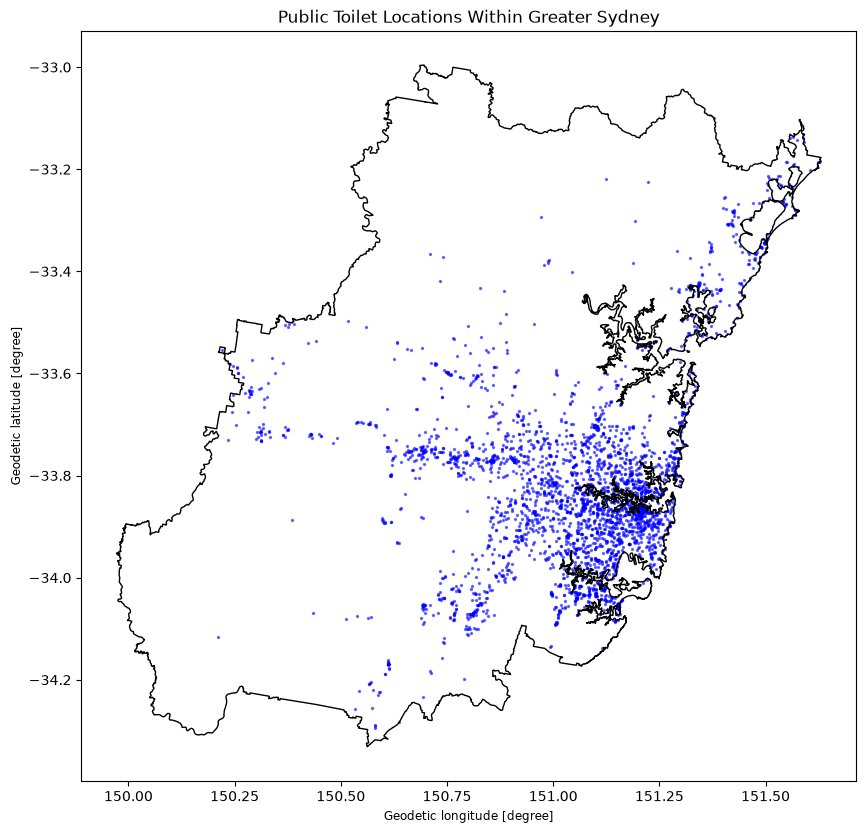

In [23]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Select the Greater Sydney boundary
sydney_boundary = boundaries[
    boundaries["GCC_NAME26"] == "Greater Sydney"
].copy()

assert len(sydney_boundary) == 1, (
    f"Expected 1 boundary, found {len(sydney_boundary)}"
)

# Load the original national dataset, not the earlier Sydney subset
toilets = pd.read_csv("../data/raw/national_toilets.csv")

# Convert toilet locations to geographic points
toilet_points = gpd.GeoDataFrame(
    toilets.dropna(subset=["Longitude", "Latitude"]).copy(),
    geometry=gpd.points_from_xy(
        toilets.dropna(subset=["Longitude", "Latitude"])["Longitude"],
        toilets.dropna(subset=["Longitude", "Latitude"])["Latitude"]
    ),
    crs="EPSG:4326"
)

# Match coordinate systems
toilet_points = toilet_points.to_crs(sydney_boundary.crs)

# Keep toilets inside Greater Sydney
sydney_toilets = gpd.sjoin(
    toilet_points,
    sydney_boundary[["geometry"]],
    how="inner",
    predicate="within"
).drop(columns=["index_right"])

print("Toilets inside Greater Sydney:", len(sydney_toilets))
print("Boundary CRS:", sydney_boundary.crs)

# Visual check
fig, ax = plt.subplots(figsize=(10, 10))
sydney_boundary.boundary.plot(ax=ax, color="black", linewidth=1)
sydney_toilets.plot(ax=ax, markersize=2, color="blue", alpha=0.5)
ax.set_title("Public Toilet Locations Within Greater Sydney")
plt.show()

# Save the filtered dataset
columns = [
    "FacilityID", "Name", "FacilityType",
    "Town", "Latitude", "Longitude"
]
sydney_toilets[columns].to_csv(
    "../data/processed/sydney_toilets.csv",
    index=False
)

In [24]:
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

folder = Path("../data/raw/abs_suburbs")
shp_files = list(folder.glob("*.shp"))

print(shp_files)

[PosixPath('../data/raw/abs_suburbs/SAL_2026_AUST_GDA2020.shp')]


In [25]:
suburbs = gpd.read_file(shp_files[0])

print("Number of geographic areas:", len(suburbs))
print(suburbs.columns.tolist())
display(suburbs.head())

Number of geographic areas: 15377
['SAL_CODE26', 'SAL_NAME26', 'STE_CODE26', 'STE_NAME26', 'AUS_CODE26', 'AUS_NAME26', 'AREASQKM26', 'geometry']


,SAL_CODE26,SAL_NAME26,STE_CODE26,STE_NAME26,AUS_CODE26,AUS_NAME26,AREASQKM26,geometry
0,10001,Aarons Pass,1,New South Wales,AUS,Australia,82.7639,"POLYGON ((149.82477 -32.84384, 149.83271 -32.8..."
1,10002,Abbotsbury,1,New South Wales,AUS,Australia,4.9788,"POLYGON ((150.86523 -33.88264, 150.86479 -33.8..."
2,10003,Abbotsford (NSW),1,New South Wales,AUS,Australia,1.0180,"POLYGON ((151.13472 -33.85492, 151.13445 -33.8..."
3,10004,Abercrombie,1,New South Wales,AUS,Australia,2.9775,"POLYGON ((149.55192 -33.3928, 149.55148 -33.39..."
4,10005,Abercrombie River,1,New South Wales,AUS,Australia,127.1701,"POLYGON ((149.25562 -33.96535, 149.25563 -33.9..."


In [26]:
## FILTER TO GREATER SYDNEY
# Ensure both datasets use the same coordinate system
suburbs = suburbs.to_crs(sydney_boundary.crs)

# Select NSW suburbs
nsw_suburbs = suburbs[
    suburbs["STE_NAME26"] == "New South Wales"
].copy()

# Keep suburbs whose representative point falls within Greater Sydney
sydney_shape = sydney_boundary.geometry.union_all()

sydney_suburbs = nsw_suburbs[
    nsw_suburbs.geometry.representative_point().intersects(sydney_shape)
].copy()

print("Suburbs in Greater Sydney:", len(sydney_suburbs))

display(
    sydney_suburbs[
        ["SAL_NAME26", "AREASQKM26"]
    ].sort_values("SAL_NAME26")
)

Suburbs in Greater Sydney: 932


,SAL_NAME26,AREASQKM26
1,Abbotsbury,4.9788
2,Abbotsford (NSW),1.0180
13,Acacia Gardens,1.0013
20,Agnes Banks,15.4750
21,Airds,2.3444
...,...,...
4531,Yellow Rock,18.8096
4535,Yennora,2.7387
4538,Yerranderie,162.2912
4548,Yowie Bay,1.2045


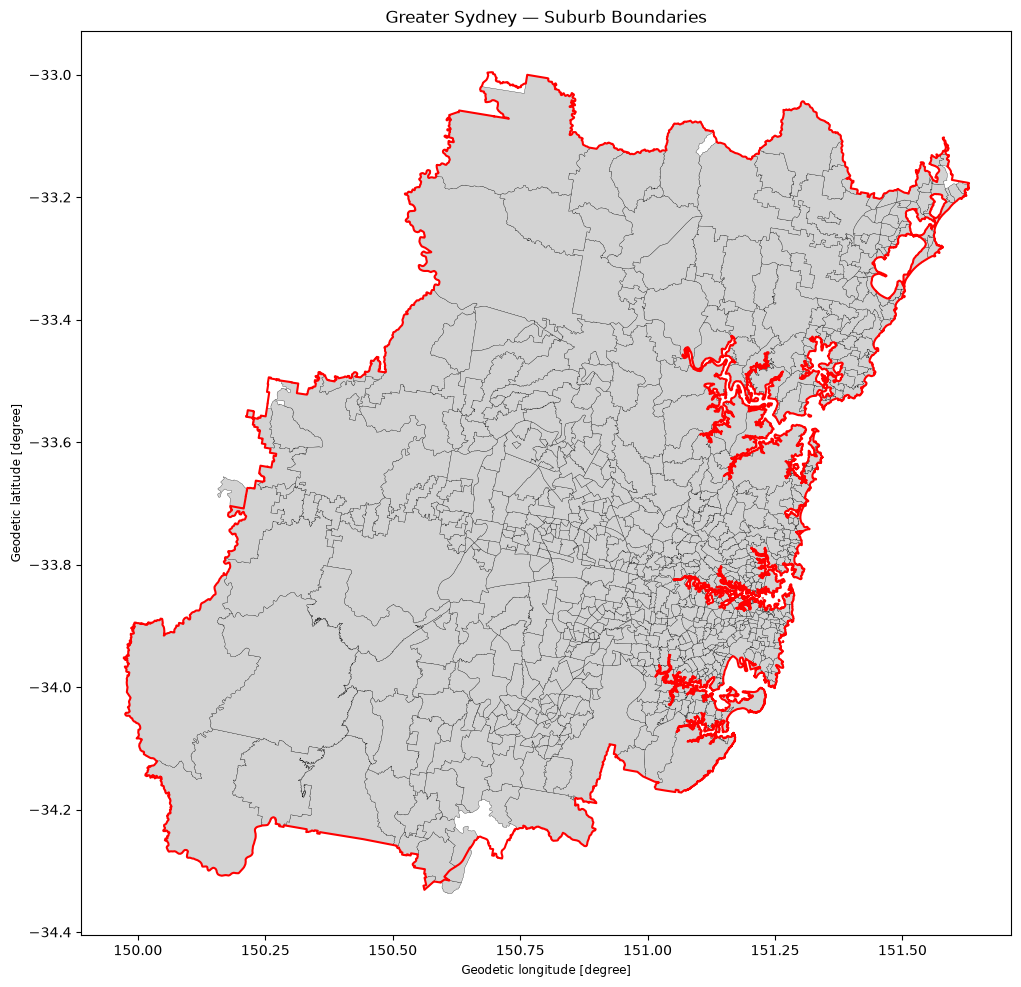

In [27]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 12))

sydney_suburbs.plot(
    ax=ax,
    facecolor="lightgrey",
    edgecolor="black",
    linewidth=0.2
)

sydney_boundary.boundary.plot(
    ax=ax,
    color="red",
    linewidth=1.5
)

ax.set_title("Greater Sydney — Suburb Boundaries")
plt.show()

In [28]:
## FIND CENSUS FILE ABOUT POPULATION (G01)
from pathlib import Path

census_folder = Path("../data/raw/census_2021")

# Find all CSV files recursively
csv_files = list(census_folder.rglob("*.csv"))

print("Total CSV files:", len(csv_files))

# Find files associated with table G01
g01_files = [
    file for file in csv_files
    if "G01" in file.name.upper()
]

for file in g01_files:
    print(file)

Total CSV files: 119
../data/raw/census_2021/2021 Census GCP Statistical Area 1 for NSW/2021Census_G01_NSW_SA1.csv


In [29]:
import pandas as pd

g01 = pd.read_csv(g01_files[0], low_memory=False)

print("Shape:", g01.shape)
print("Columns:")
print(g01.columns.tolist())

display(g01.head())

Shape: (19750, 109)
Columns:
['SA1_CODE_2021', 'Tot_P_M', 'Tot_P_F', 'Tot_P_P', 'Age_0_4_yr_M', 'Age_0_4_yr_F', 'Age_0_4_yr_P', 'Age_5_14_yr_M', 'Age_5_14_yr_F', 'Age_5_14_yr_P', 'Age_15_19_yr_M', 'Age_15_19_yr_F', 'Age_15_19_yr_P', 'Age_20_24_yr_M', 'Age_20_24_yr_F', 'Age_20_24_yr_P', 'Age_25_34_yr_M', 'Age_25_34_yr_F', 'Age_25_34_yr_P', 'Age_35_44_yr_M', 'Age_35_44_yr_F', 'Age_35_44_yr_P', 'Age_45_54_yr_M', 'Age_45_54_yr_F', 'Age_45_54_yr_P', 'Age_55_64_yr_M', 'Age_55_64_yr_F', 'Age_55_64_yr_P', 'Age_65_74_yr_M', 'Age_65_74_yr_F', 'Age_65_74_yr_P', 'Age_75_84_yr_M', 'Age_75_84_yr_F', 'Age_75_84_yr_P', 'Age_85ov_M', 'Age_85ov_F', 'Age_85ov_P', 'Counted_Census_Night_home_M', 'Counted_Census_Night_home_F', 'Counted_Census_Night_home_P', 'Count_Census_Nt_Ewhere_Aust_M', 'Count_Census_Nt_Ewhere_Aust_F', 'Count_Census_Nt_Ewhere_Aust_P', 'Indigenous_psns_Aboriginal_M', 'Indigenous_psns_Aboriginal_F', 'Indigenous_psns_Aboriginal_P', 'Indig_psns_Torres_Strait_Is_M', 'Indig_psns_Torres_Strait_

,SA1_CODE_2021,Tot_P_M,Tot_P_F,Tot_P_P,Age_0_4_yr_M,Age_0_4_yr_F,Age_0_4_yr_P,Age_5_14_yr_M,Age_5_14_yr_F,Age_5_14_yr_P,...,High_yr_schl_comp_Yr_8_belw_P,High_yr_schl_comp_D_n_g_sch_M,High_yr_schl_comp_D_n_g_sch_F,High_yr_schl_comp_D_n_g_sch_P,Count_psns_occ_priv_dwgs_M,Count_psns_occ_priv_dwgs_F,Count_psns_occ_priv_dwgs_P,Count_Persons_other_dwgs_M,Count_Persons_other_dwgs_F,Count_Persons_other_dwgs_P
0,10102100701,179,128,305,6,9,7,12,5,18,...,8,0,0,0,154,122,275,13,10,26
1,10102100702,148,156,301,3,7,8,5,14,22,...,5,0,0,0,138,138,273,16,19,36
2,10102100703,244,234,471,21,10,30,43,29,73,...,12,0,0,0,224,206,433,10,23,39
3,10102100704,232,284,522,9,7,15,33,27,58,...,14,0,3,4,195,240,427,52,50,96
4,10102100705,206,214,423,12,9,26,31,8,47,...,16,0,0,0,182,188,367,30,18,49


In [30]:
population = g01[["SA1_CODE_2021", "Tot_P_P"]].copy()

population = population.rename(columns={
    "SA1_CODE_2021": "sa1_code",
    "Tot_P_P": "population"
})

print("Number of SA1 areas:", len(population))
display(population.head())

population.to_csv(
    "../data/processed/sa1_population_2021.csv",
    index=False
)

Number of SA1 areas: 19750


,sa1_code,population
0,10102100701,305
1,10102100702,301
2,10102100703,471
3,10102100704,522
4,10102100705,423


In [31]:
## INSPECTING 2021 shape file

In [32]:
import geopandas as gpd
from pathlib import Path

folder = Path("../data/raw/abs_sa1_2021")
shp_files = list(folder.rglob("*.shp"))

print("Found:", shp_files)

sa1_boundaries = gpd.read_file(shp_files[0])

print("Columns:", sa1_boundaries.columns.tolist())
print("CRS:", sa1_boundaries.crs)
display(sa1_boundaries.head())

Found: [PosixPath('../data/raw/abs_sa1_2021/SA1_2021_AUST_GDA2020.shp')]
Columns: ['SA1_CODE21', 'CHG_FLAG21', 'CHG_LBL21', 'SA2_CODE21', 'SA2_NAME21', 'SA3_CODE21', 'SA3_NAME21', 'SA4_CODE21', 'SA4_NAME21', 'GCC_CODE21', 'GCC_NAME21', 'STE_CODE21', 'STE_NAME21', 'AUS_CODE21', 'AUS_NAME21', 'AREASQKM21', 'LOCI_URI21', 'geometry']
CRS: EPSG:7844


,SA1_CODE21,CHG_FLAG21,CHG_LBL21,SA2_CODE21,SA2_NAME21,SA3_CODE21,SA3_NAME21,SA4_CODE21,SA4_NAME21,GCC_CODE21,GCC_NAME21,STE_CODE21,STE_NAME21,AUS_CODE21,AUS_NAME21,AREASQKM21,LOCI_URI21,geometry
0,10102100701,0,No change,101021007,Braidwood,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,AUS,Australia,362.8727,http://linked.data.gov.au/dataset/asgsed3/SA1/...,"POLYGON ((149.89111 -35.08989, 149.89181 -35.0..."
1,10102100702,0,No change,101021007,Braidwood,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,AUS,Australia,229.7459,http://linked.data.gov.au/dataset/asgsed3/SA1/...,"POLYGON ((149.73421 -35.36757, 149.74475 -35.3..."
2,10102100703,0,No change,101021007,Braidwood,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,AUS,Australia,2.3910,http://linked.data.gov.au/dataset/asgsed3/SA1/...,"POLYGON ((149.77998 -35.44066, 149.77997 -35.4..."
3,10102100704,0,No change,101021007,Braidwood,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,AUS,Australia,1.2816,http://linked.data.gov.au/dataset/asgsed3/SA1/...,"POLYGON ((149.79744 -35.44148, 149.79779 -35.4..."
4,10102100705,0,No change,101021007,Braidwood,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,AUS,Australia,1.1978,http://linked.data.gov.au/dataset/asgsed3/SA1/...,"POLYGON ((149.79499 -35.44901, 149.79518 -35.4..."


In [33]:
## calculate population density for each SA
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Load cleaned population data
population = pd.read_csv(
    "../data/processed/sa1_population_2021.csv",
    dtype={"sa1_code": str}
)

# Ensure SA1 codes have the same data type
sa1_boundaries["SA1_CODE21"] = sa1_boundaries["SA1_CODE21"].astype(str)

# Join population onto geographic boundaries
sa1 = sa1_boundaries.merge(
    population,
    left_on="SA1_CODE21",
    right_on="sa1_code",
    how="left",
    validate="one_to_one"
)

# Calculate population density (people per km²)
sa1["pop_density"] = (
    sa1["population"] / sa1["AREASQKM21"].replace(0, float("nan"))
)

print("Total SA1 areas:", len(sa1))
print("SA1 areas without population data:", sa1["population"].isna().sum())

display(sa1[
    ["SA1_CODE21", "SA2_NAME21", "population", "AREASQKM21", "pop_density"]
].head())

Total SA1 areas: 61845
SA1 areas without population data: 42095


,SA1_CODE21,SA2_NAME21,population,AREASQKM21,pop_density
0,10102100701,Braidwood,305.0,362.8727,0.840515
1,10102100702,Braidwood,301.0,229.7459,1.310143
2,10102100703,Braidwood,471.0,2.3910,196.988708
3,10102100704,Braidwood,522.0,1.2816,407.303371
4,10102100705,Braidwood,423.0,1.1978,353.147437


In [34]:
sydney_sa1 = sa1[
    sa1["GCC_NAME21"] == "Greater Sydney"
].copy()

print("Greater Sydney SA1 areas:", len(sydney_sa1))
print("Total population:", sydney_sa1["population"].sum())

Greater Sydney SA1 areas: 12175
Total population: 5231341.0


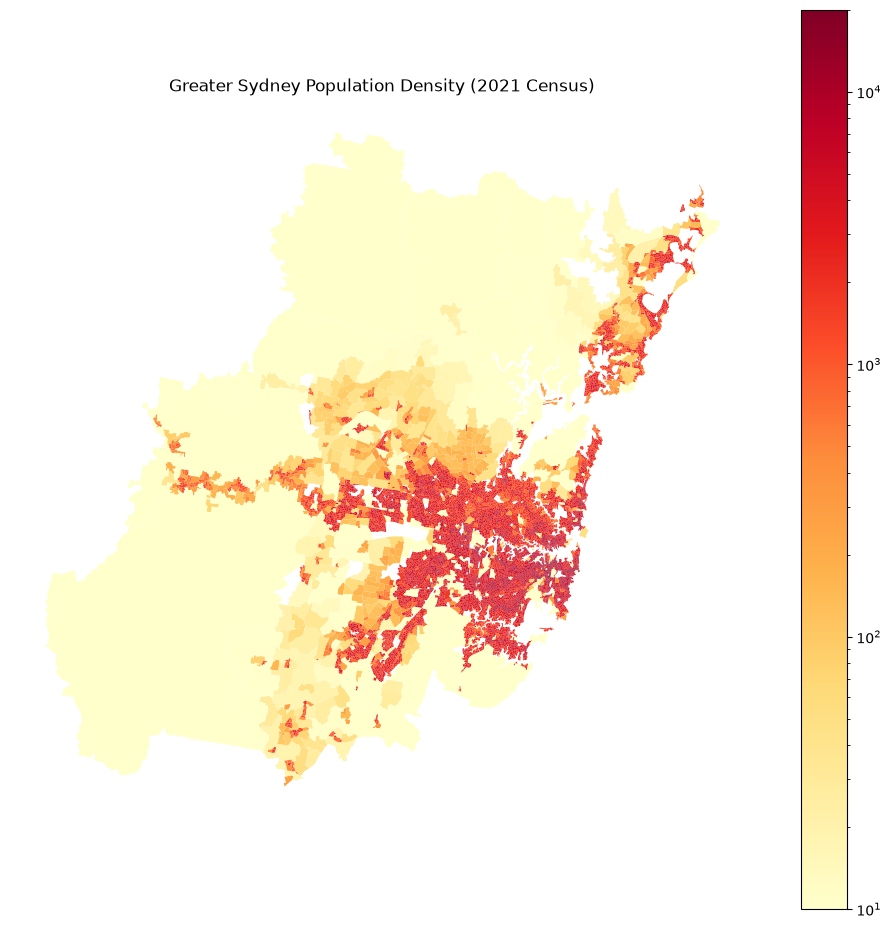

In [35]:
## sydney population density map
import matplotlib.colors as colors

fig, ax = plt.subplots(figsize=(12, 12))

sydney_sa1.plot(
    column="pop_density",
    ax=ax,
    cmap="YlOrRd",
    norm=colors.LogNorm(vmin=10, vmax=20000),
    legend=True,
    missing_kwds={"color": "lightgrey"},
    linewidth=0
)

ax.set_title("Greater Sydney Population Density (2021 Census)")
ax.set_axis_off()

plt.show()

In [36]:
## inspect density distribution
print(
    sydney_sa1["pop_density"].describe(
        percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
    )
)

# Count SA1s at different population densities
for threshold in [100, 300, 500, 1000, 2000]:
    count = (sydney_sa1["pop_density"] < threshold).sum()
    print(f"Below {threshold} people/km²: {count} SA1s")

count     12175.000000
mean       5890.308361
std       10649.506058
min           0.000000
10%         770.892864
25%        2295.697331
50%        3553.095118
75%        5580.346292
90%       11731.413838
max      516666.666667
Name: pop_density, dtype: float64
Below 100 people/km²: 670 SA1s
Below 300 people/km²: 908 SA1s
Below 500 people/km²: 1037 SA1s
Below 1000 people/km²: 1392 SA1s
Below 2000 people/km²: 2514 SA1s


In [49]:
## set a density threshold to exclude rural areas
DENSITY_THRESHOLD = 50

urban_sa1 = sydney_sa1[
    sydney_sa1["pop_density"] >= DENSITY_THRESHOLD
].copy()

print("Original SA1s:", len(sydney_sa1))
print("Urban SA1s:", len(urban_sa1))
print("Excluded SA1s:", len(sydney_sa1) - len(urban_sa1))

Original SA1s: 12175
Urban SA1s: 11612
Excluded SA1s: 563


In [ ]:
## SEE WHATS LEFT

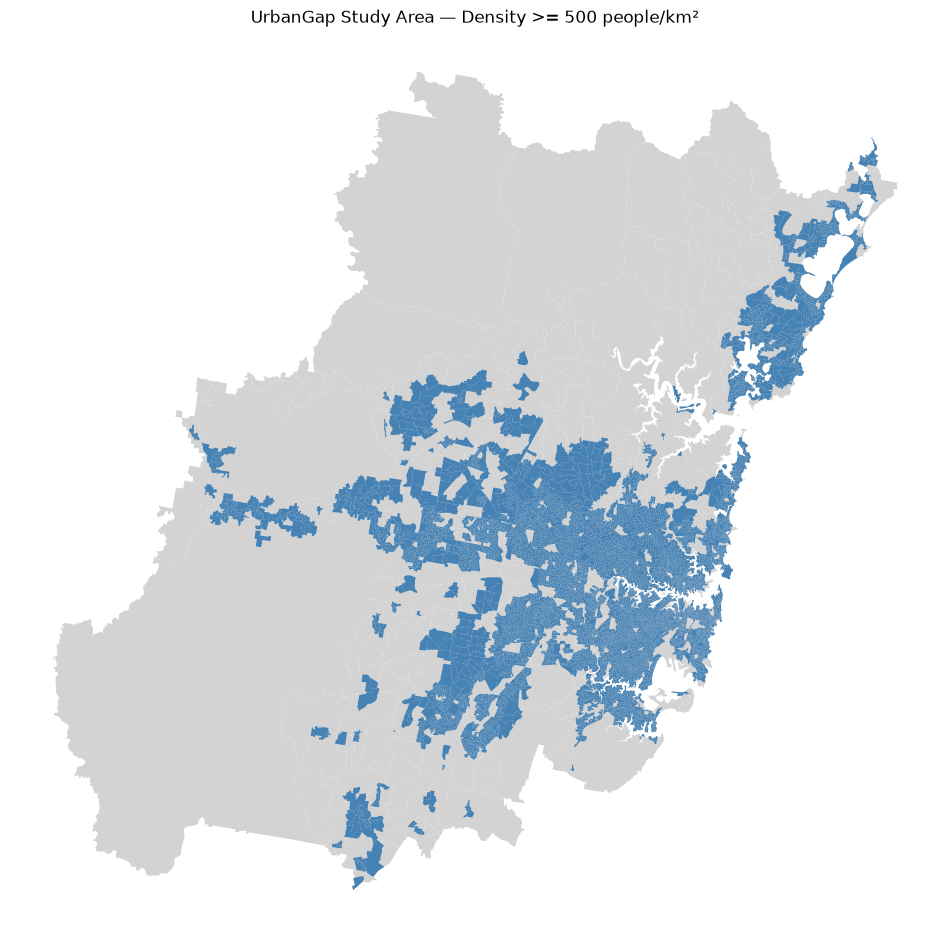

In [50]:
fig, ax = plt.subplots(figsize=(12, 12))

# All Sydney SA1 areas in light grey
sydney_sa1.plot(
    ax=ax,
    color="lightgrey",
    linewidth=0
)

# Retained urban areas in blue
urban_sa1.plot(
    ax=ax,
    color="steelblue",
    linewidth=0
)

ax.set_title("UrbanGap Study Area — Density >= 500 people/km²")
ax.set_axis_off()

plt.show()

In [51]:
# Merge all retained SA1 polygons into a single geometry
merged = urban_sa1.geometry.union_all()

# Separate disconnected polygon components
components = (
    list(merged.geoms)
    if merged.geom_type == "MultiPolygon"
    else [merged]
)

# Create a GeoDataFrame of connected components
clusters = gpd.GeoDataFrame(
    {"cluster_id": range(len(components))},
    geometry=components,
    crs=urban_sa1.crs
)

# Calculate area in a projected CRS
clusters["area_km2"] = (
    clusters.to_crs("EPSG:7856").area / 1_000_000
)

print("Number of connected clusters:", len(clusters))

display(
    clusters.nlargest(10, "area_km2")[
        ["cluster_id", "area_km2"]
    ]
)

Number of connected clusters: 68


,cluster_id,area_km2
8,8,1660.364797
62,62,255.515687
47,47,125.618597
20,20,117.636036
28,28,85.349520
13,13,70.692643
1,1,58.785230
39,39,47.145572
38,38,18.157962
61,61,17.991822


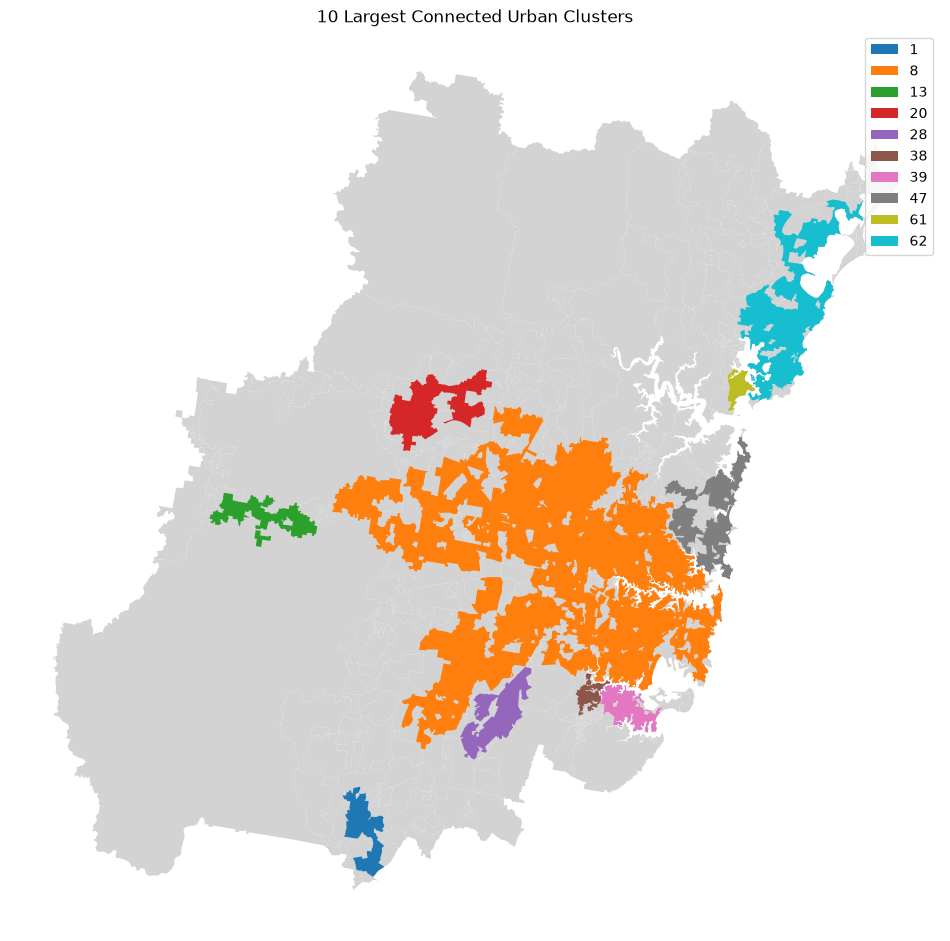

In [52]:
fig, ax = plt.subplots(figsize=(12, 12))

sydney_sa1.plot(ax=ax, color="lightgrey", linewidth=0)

clusters.nlargest(10, "area_km2").plot(
    ax=ax,
    column="cluster_id",
    categorical=True,
    cmap="tab10",
    legend=True
)

ax.set_title("10 Largest Connected Urban Clusters")
ax.set_axis_off()
plt.show()

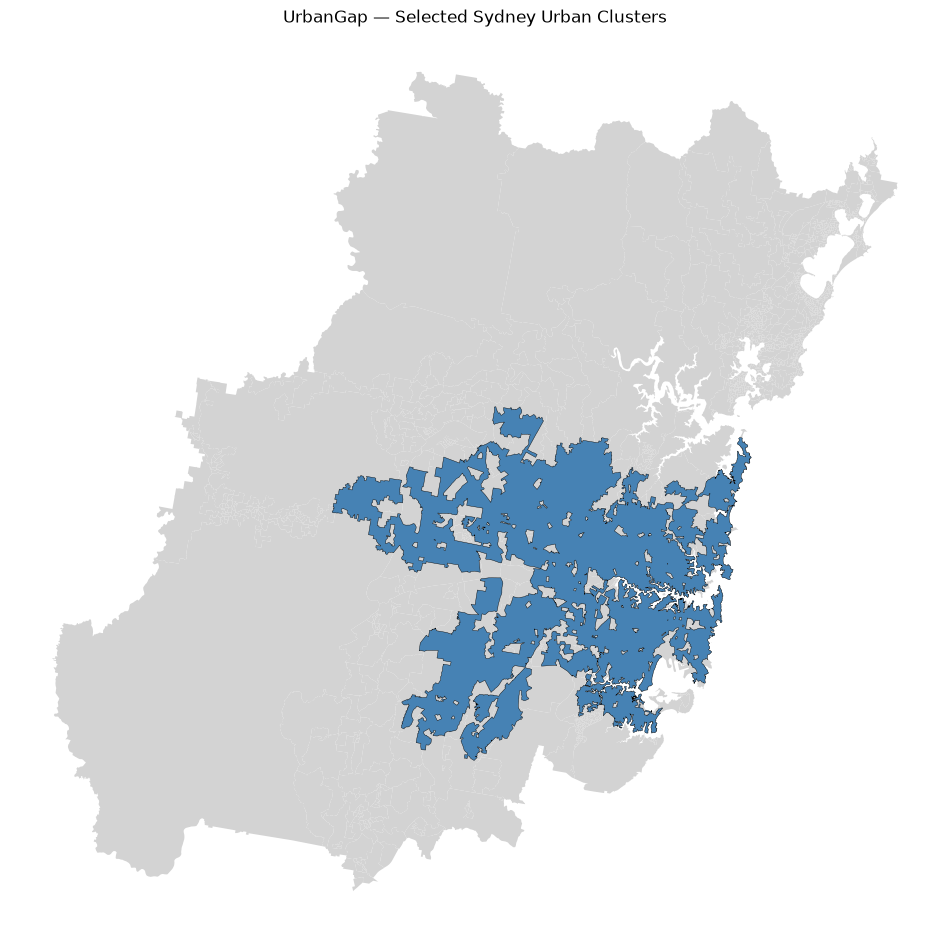

In [53]:
## SELECT SYDNEY CLUSTERS
selected_cluster_ids = [8, 47, 28, 38, 39]

selected_clusters = clusters[
    clusters["cluster_id"].isin(selected_cluster_ids)
].copy()

fig, ax = plt.subplots(figsize=(12, 12))

sydney_sa1.plot(ax=ax, color="lightgrey", linewidth=0)

selected_clusters.plot(
    ax=ax,
    color="steelblue",
    edgecolor="black",
    linewidth=0.3
)

ax.set_title("UrbanGap — Selected Sydney Urban Clusters")
ax.set_axis_off()
plt.show()

In [55]:
## INCLUDE NEARBY LOW DENSITY
# Work in metres using a projected coordinate system
selected_projected = selected_clusters.to_crs("EPSG:7856")
sa1_projected = sydney_sa1.to_crs("EPSG:7856")

# Expand the selected urban areas by 500 metres
expanded_area = selected_projected.geometry.union_all().buffer(500)

# Include SA1s whose representative points fall inside expanded area
study_sa1 = sa1_projected[
    sa1_projected.geometry.representative_point().intersects(expanded_area)
].copy()

print("SA1s in preliminary study area:", len(study_sa1))

SA1s in preliminary study area: 10753


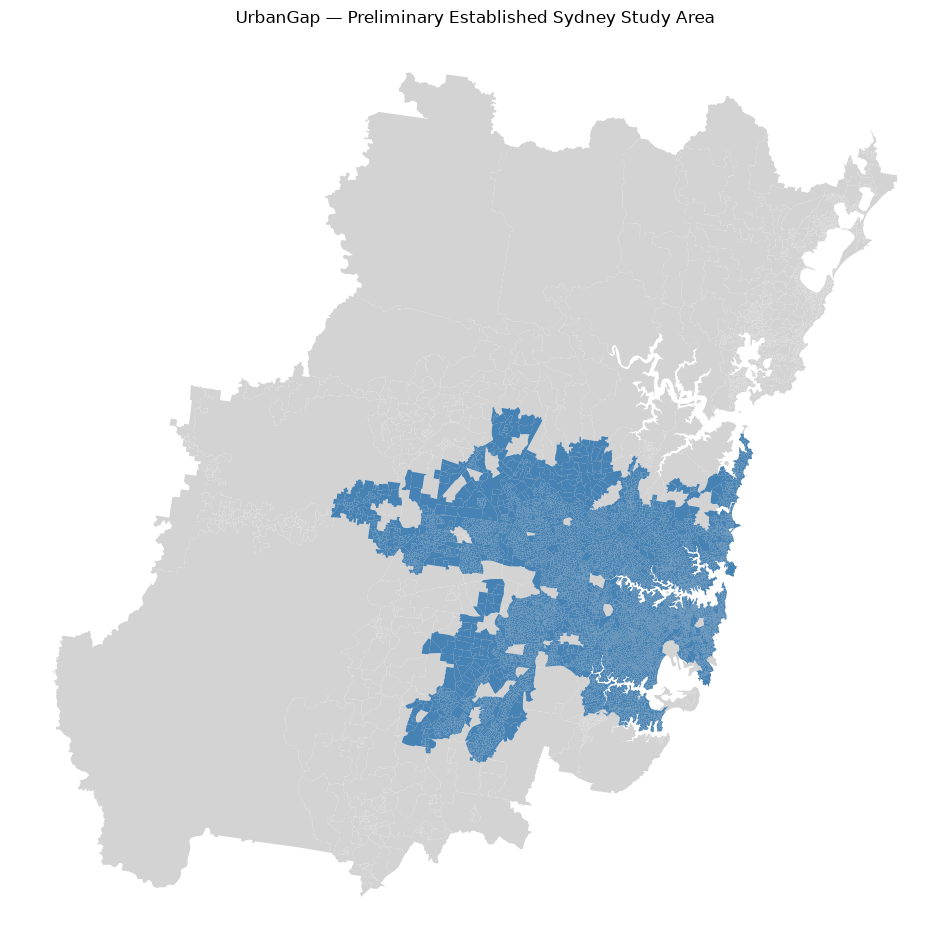

In [56]:
fig, ax = plt.subplots(figsize=(12, 12))

sydney_sa1.to_crs("EPSG:7856").plot(
    ax=ax,
    color="lightgrey",
    linewidth=0
)

study_sa1.plot(
    ax=ax,
    color="steelblue",
    linewidth=0
)

ax.set_title("UrbanGap — Preliminary Established Sydney Study Area")
ax.set_axis_off()
plt.show()

In [57]:
study_sa1.to_file(
    "../data/processed/sydney_study_sa1_preliminary.geojson",
    driver="GeoJSON"
)

In [65]:
## DEFINE THE GROWTH CORRIDORS TO EXCLUDE
growth_suburbs = [
    # North West Growth Area
    "Box Hill (NSW)",
    "Marsden Park",
    "Riverstone",
    "Schofields",
    "Vineyard",
    "Shanes Park",
    "Colebee",

    # South West Growth Area
    "Austral",
    "Leppington",
    "Catherine Field",
    "Oran Park",
    "Gregory Hills",
    "Gledswood Hills",
    "Edmondson Park",

    # Western Sydney Aerotropolis
    "Badgerys Creek",
    "Luddenham",
    "Bringelly",

    # Greater Macarthur greenfield areas
    "Appin (NSW)",
    "Gilead",
    "Menangle Park"
]

In [66]:
## find names
# Convert suburbs to the same CRS as the study area
suburbs_projected = sydney_suburbs.to_crs(study_sa1.crs)

# Find matching suburbs
growth_polygons = suburbs_projected[
    suburbs_projected["SAL_NAME26"].isin(growth_suburbs)
].copy()

print("Matched growth suburbs:")
print(growth_polygons["SAL_NAME26"].tolist())

print("\nNames not found:")
print(sorted(
    set(growth_suburbs) -
    set(growth_polygons["SAL_NAME26"])
))

Matched growth suburbs:
['Appin (NSW)', 'Austral', 'Badgerys Creek', 'Box Hill (NSW)', 'Bringelly', 'Catherine Field', 'Colebee', 'Edmondson Park', 'Gilead', 'Gledswood Hills', 'Gregory Hills', 'Leppington', 'Luddenham', 'Marsden Park', 'Menangle Park', 'Oran Park', 'Riverstone', 'Schofields', 'Shanes Park', 'Vineyard']

Names not found:
[]


In [67]:
growth_area = growth_polygons.geometry.union_all()

study_sa1_filtered = study_sa1[
    ~study_sa1.geometry.representative_point().intersects(growth_area)
].copy()

print("SA1s before:", len(study_sa1))
print("SA1s after:", len(study_sa1_filtered))
print("Excluded:", len(study_sa1) - len(study_sa1_filtered))

SA1s before: 10753
SA1s after: 10503
Excluded: 250


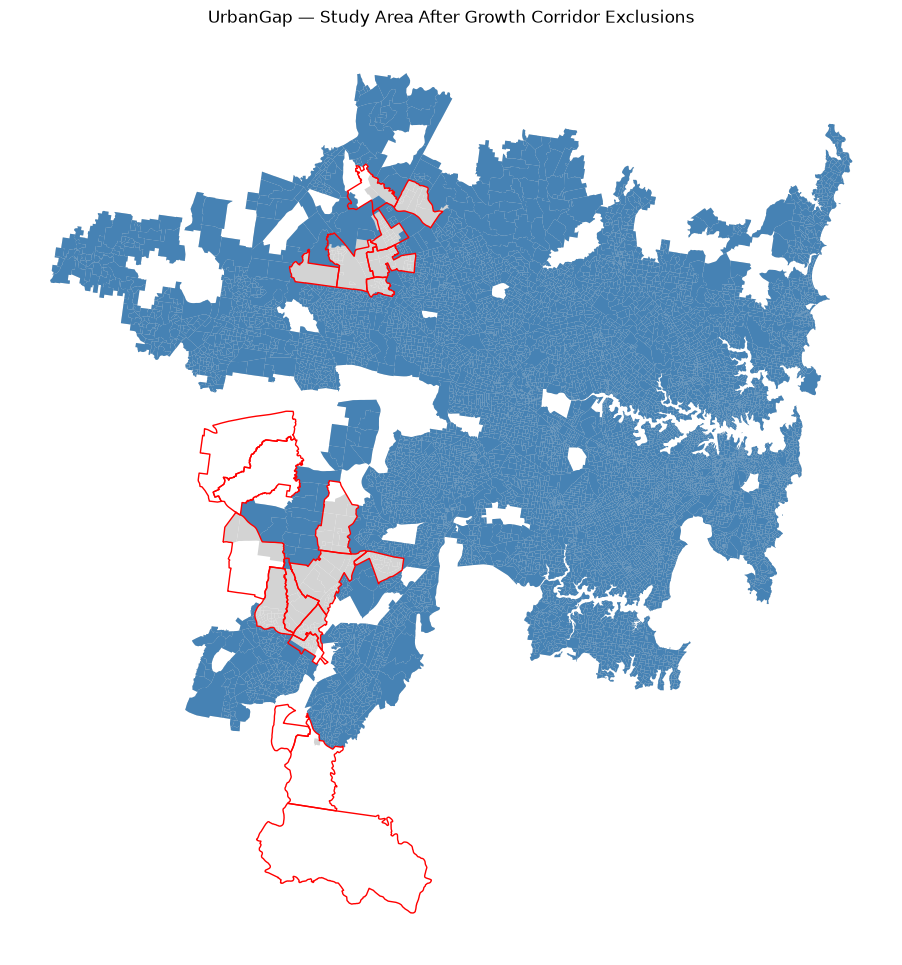

In [68]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 12))

# Original study area
study_sa1.plot(
    ax=ax,
    color="lightgrey",
    linewidth=0
)

# Remaining study area
study_sa1_filtered.plot(
    ax=ax,
    color="steelblue",
    linewidth=0
)

# Growth suburb outlines
growth_polygons.boundary.plot(
    ax=ax,
    color="red",
    linewidth=1
)

ax.set_title("UrbanGap — Study Area After Growth Corridor Exclusions")
ax.set_axis_off()

plt.show()

In [69]:
study_sa1_filtered.to_file(
    "../data/processed/sydney_study_sa1_final.geojson",
    driver="GeoJSON"
)